# 大模型微调 04：金融提示词应用实战

本篇整理 `04-笔记`、`04-课件`、`04-代码` 和 `04-附属资料` 中的内容，围绕金融行业的三类大模型应用展开：**金融文本分类、金融信息抽取、金融文本匹配**。核心方法是使用 Ollama 在本地运行 Qwen2.5，并通过明确的 Prompt、few-shot 示例和结构化输出约束模型。

本章重点不在训练新模型，而在于把业务任务定义清楚、把输入输出约束清楚，并通过迭代 Prompt 获得稳定结果。


## 一、项目背景与总体流程

金融数据增长很快，投资者和研究者需要从公告、新闻、报告和股票文本中快速获得有效信息。传统方法通常需要 NLP、机器学习和特征工程知识；大模型让非专业人员也可以通过 Prompt 直接完成部分金融分析任务。

本章三个应用场景：

1. **文本分类**：判断金融文本属于新闻报道、公司公告、财务公告还是分析师报告。
2. **信息抽取**：从股票文本中抽取日期、股票名称、开盘价、收盘价和成交量等字段。
3. **文本匹配**：判断两段金融文本是否表达相似语义。

统一流程是：

```text
定义业务任务 → 设计 Prompt → 加入 few-shot 示例 → 规定输出格式 → 调用本地模型 → 检查和清洗结果
```


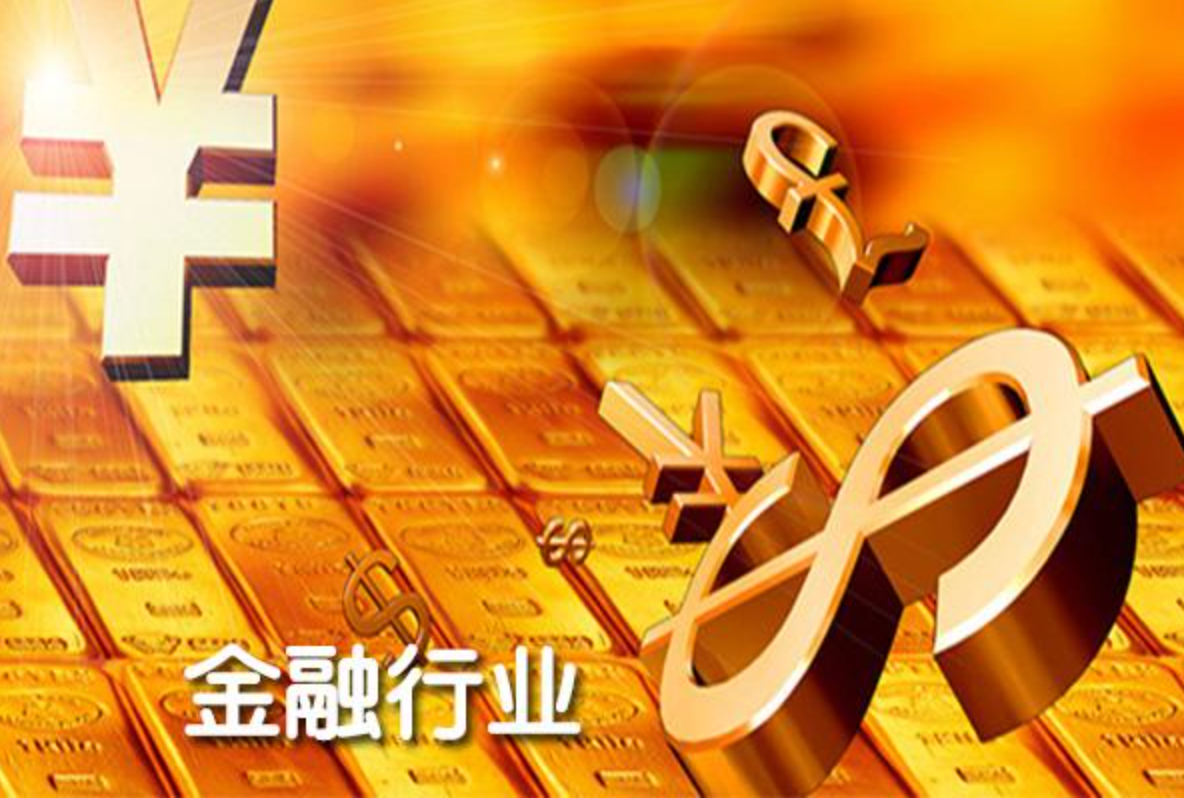

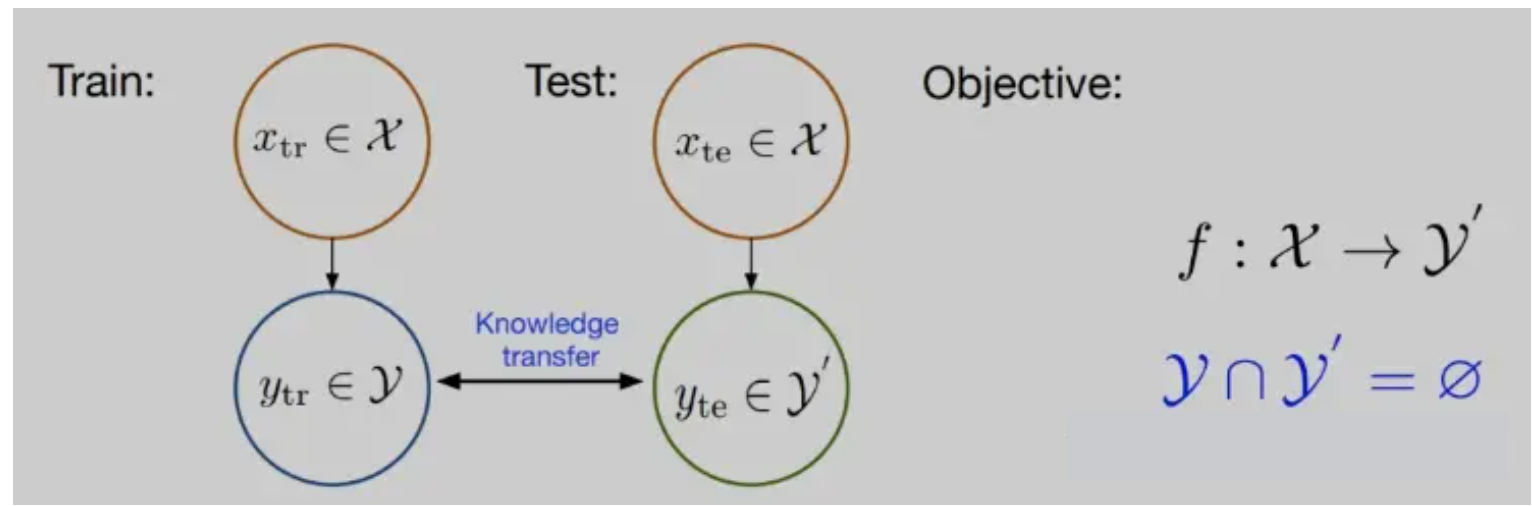

## 二、运行环境与模型选择

课件项目使用 Qwen2.5:7b 或 ChatGLM-6B。Day04 的代码统一通过 Ollama 调用：

```bash
ollama run qwen2.5:7b
```

如果使用 ChatGLM-6B，需要约 12GB 以上磁盘空间，加载模型大约需要 13GB 显存；显存不足时应使用量化模型。Python 侧需要安装：

```bash
pip install ollama rich
```

金融信息抽取还使用标准库 `json` 和 `re` 做结果解析与后处理。


## 三、金融文本分类

### 3.1 任务定义

例如：

```text
公司资产负债表显示，公司偿债能力强劲，现金流充足，为未来投资和扩张提供了坚实的财务基础。
```

目标是从 `新闻报道`、`公司公告`、`财务报告`、`分析师报告` 中选择一个类别。

Prompt 需要同时说明：

- 你现在是什么角色；
- 分类候选集合有哪些；
- 如何理解分类任务；
- 最终只能返回指定类别，避免多余解释。


### 3.2 few-shot Prompt 设计

先在历史消息中放入人工标注的示例：

```text
User：今日，股市经历了一轮震荡……是 ['新闻报道','公司公告','财务报告','分析师报告'] 里的什么类别？
Bot：新闻报道

User：本公司年度财务报告显示……是 ['新闻报道','公司公告','财务报告','分析师报告'] 里的什么类别？
Bot：财务报告
```

模型看到这些示例后，才能理解类别边界和回答格式。示例中的 Bot 内容是人工提供的，不是模型实时生成的。


### 3.3 分类代码

下面保留 `04-代码/finance_classify.py` 的完整实现：


```python
# —*-coding:utf-8-*-
"""
利用 LLM 进行文本分类任务。
"""
# rich第三方库，用来美化终端输出结果
# from pprint import pprint
from rich import print
from rich.console import Console
import ollama


# 提供所有类别以及每个类别下的样例
class_examples = {
    '新闻报道': '今日，股市经历了一轮震荡，受到宏观经济数据和全球贸易紧张局势的影响。投资者密切关注美联储可能的政策调整，以适应市场的不确定性。',
    '财务报告': '本公司年度财务报告显示，去年公司实现了稳步增长的盈利，同时资产负债表呈现强劲的状况。经济环境的稳定和管理层的有效战略执行为公司的健康发展奠定了基础。',
    '公司公告': '本公司高兴地宣布成功完成最新一轮并购交易，收购了一家在人工智能领域领先的公司。这一战略举措将有助于扩大我们的业务领域，提高市场竞争力',
    '分析师报告': '最新的行业分析报告指出，科技公司的创新将成为未来增长的主要推动力。云计算、人工智能和数字化转型被认为是引领行业发展的关键因素，投资者应关注这些趋势'}

def init_prompts():
    """
    初始化前置prompt，便于模型做 incontext learning。
    """
    class_list = list(class_examples.keys())
    pre_history = [{"role": "system", "content": f"现在你是一个文本分类器，你需要按照要求将我给你的句子分类到：{class_list}类别中。"}, ]

    for _type, exmpale in class_examples.items():
        # print(f'“{exmpale}”是 {class_list} 里的什么类别？')
        pre_history.append({"role": "user", "content": f'“{exmpale}”是 {class_list} 里的什么类别？'})
        pre_history.append({"role": "assistant", "content":  _type})

    return {'class_list': class_list, 'pre_history': pre_history}



def inference(
        sentences: list,
        custom_settings: dict
):
    """
    推理函数。

    Args:
        sentences (List[str]): 待推理的句子。
        custom_settings (dict): 初始设定，包含人为给定的 few-shot example。
    """

    for sentence in sentences:

        with console.status("[bold bright_green] Model Inference..."):
            sentence_with_prompt = f"“{sentence}”是 {custom_settings['class_list']} 里的什么类别？"
            # print(f'sentence_with_prompt--》{sentence_with_prompt}')
            # break
            response = ollama.chat(model='qwen2.5:7b',
                                   messages=[*custom_settings['pre_history'],
                                             {"role": 'user', "content": sentence_with_prompt}])
            response = response["message"]["content"]
        print(f'>>> [bold bright_red]sentence: {sentence}')
        print(f'>>> [bold bright_green]inference answer: {response}')
        print('*' * 80)

if __name__ == '__main__':
    console = Console()

    sentences = [
        "今日，央行发布公告宣布降低利率，以刺激经济增长。这一降息举措将影响贷款利率，并在未来几个季度内对金融市场产生影响。",
        "本公司宣布成功收购一家在创新科技领域领先的公司，这一战略性收购将有助于公司拓展技术能力和加速产品研发。",
        "公司资产负债表显示，公司偿债能力强劲，现金流充足，为未来投资和扩张提供了坚实的财务基础。",
        "最新的分析报告指出，可再生能源行业预计将在未来几年经历持续增长，投资者应该关注这一领域的投资机会",
        ]

    custom_settings = init_prompts()
    # print(custom_settings)
    #
    inference(
        sentences,
        custom_settings
    )

```

实现要点：

- `class_examples` 保存类别和示例文本；
- `init_prompts()` 构造 system 指令、few-shot user/assistant 历史；
- `inference()` 为待分类句子追加用户消息；
- `ollama.chat()` 使用 `qwen2.5:7b` 返回分类结果；
- `rich` 用于显示推理状态和结果。


## 四、金融文本信息抽取

### 4.1 Schema 先行

信息抽取不能只告诉模型“提取关键信息”，还要先定义字段 Schema：

```python
schema = {
    '金融': ['日期', '股票名称', '开盘价', '收盘价', '成交量'],
}
```

例如从：

```text
2023-02-15，股票佰笃[BD]美股开盘价10美元，最终以13美元收盘，成交量增加至460,000。
```

抽取日期、股票名称、开盘价、收盘价和成交量。缺失字段统一返回 `['原文中未提及']`，多个值使用逗号分隔，最终返回 JSON。


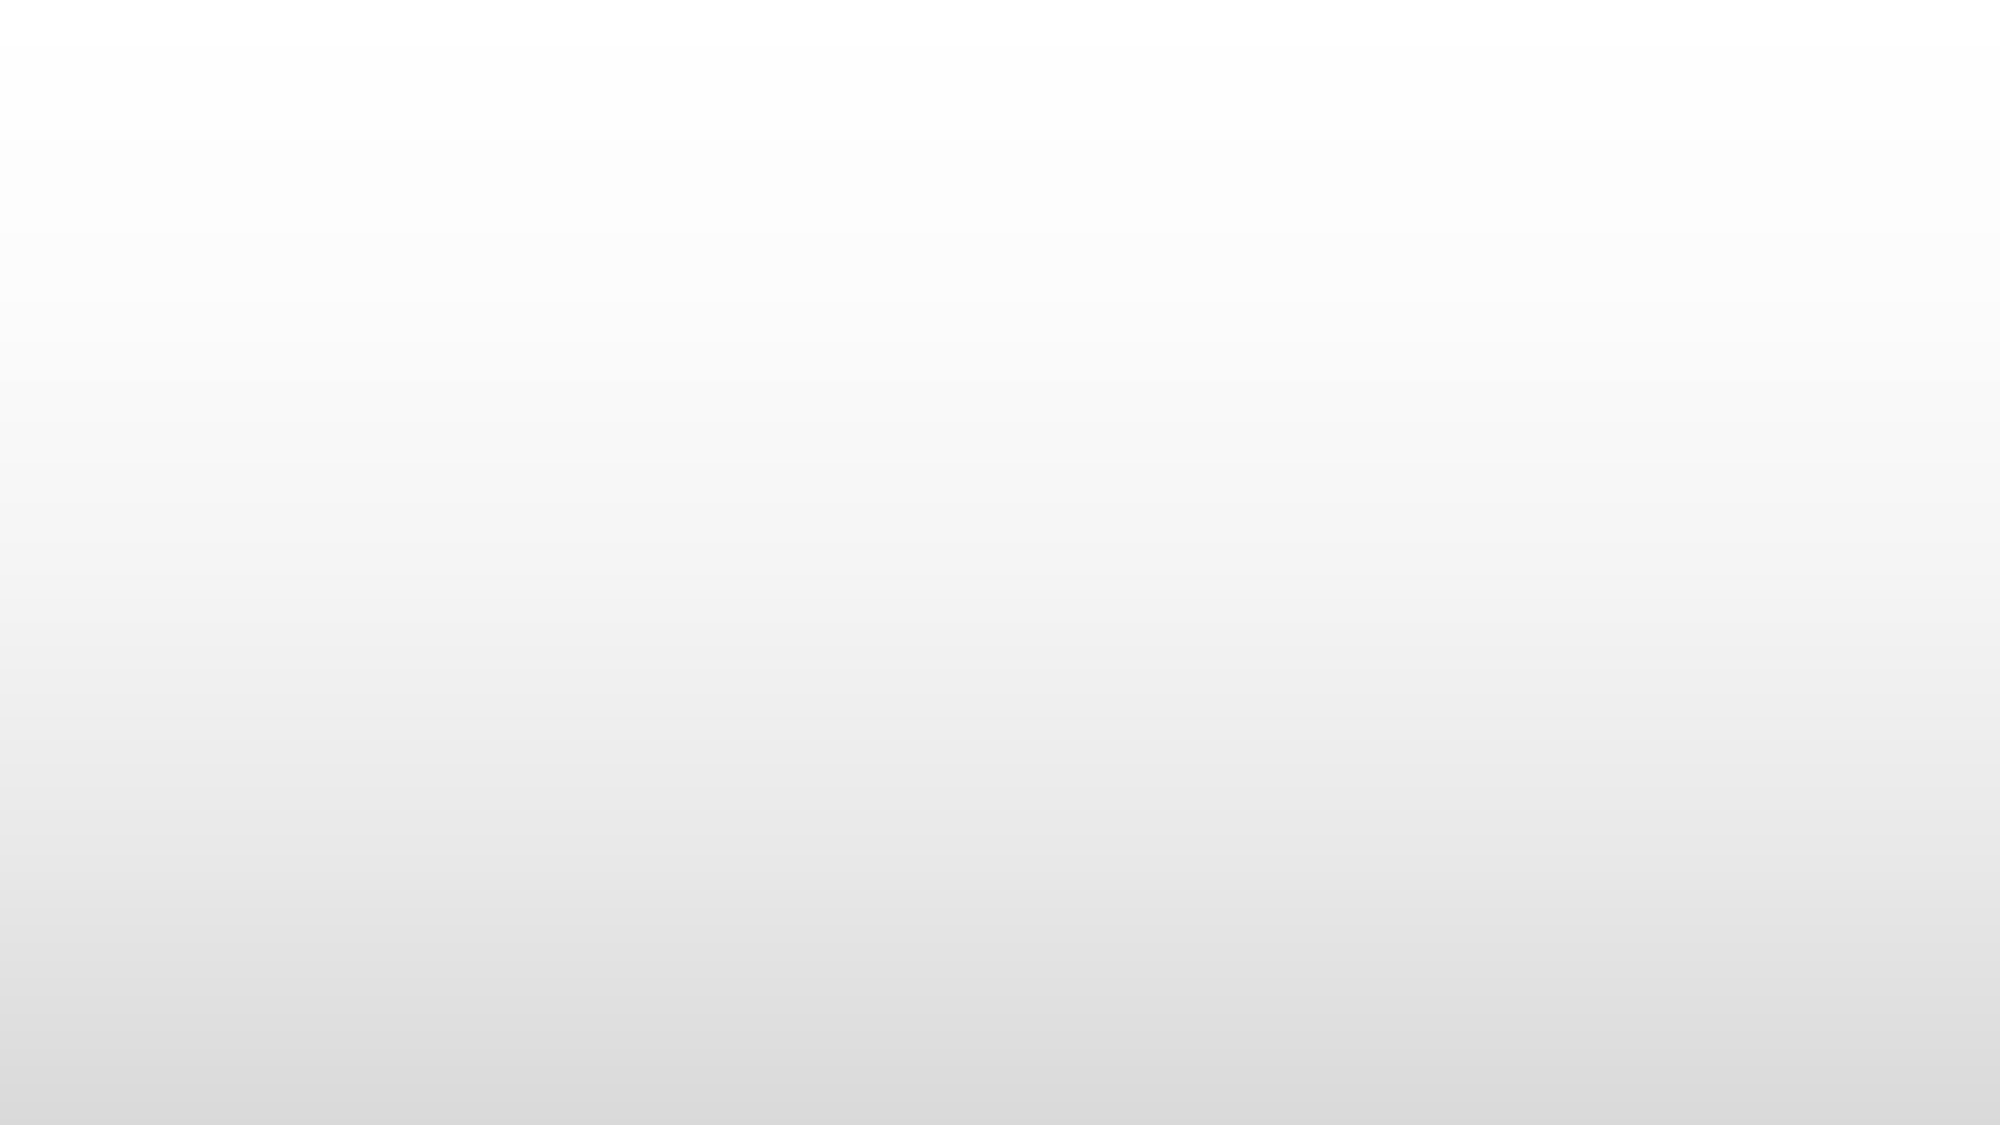

### 4.2 few-shot 抽取示例

在 Prompt 中先提供一条标注样例：

```text
输入：2023-01-10，股票古哥-D[EOOE]美股开盘价100美元，收盘价102美元，成交量520000。
输出：
{
  "日期": ["2023-01-10"],
  "股票名称": ["古哥-D[EOOE]美股"],
  "开盘价": ["100美元"],
  "收盘价": ["102美元"],
  "成交量": ["520000"]
}
```

这样模型既知道要抽取什么，也知道 JSON 的键、数组形式和缺失字段的写法。


### 4.3 抽取代码

下面保留 `04-代码/finance_ie.py`：


```python
# coding:utf-8
import json
import ollama
import re
# from rich import print

# 定义不同类型下的实体类型
schema = {
    '金融': ['日期', '股票名称', '开盘价', '收盘价', '成交量']
}

IE_PATTERN = "{}\n\n提取上述句子中{}的实体，并按照JSON格式输出，上述句子中不存在的信息用['原文中未提及']来表示，多个值之间用','分隔。"



# 提供一些例子供模型参考
ie_examples = {
    '金融': [
        {
            'content': '2023-01-10，股市震荡。股票古哥-D[EOOE]美股今日开盘价100美元，一度飙升至105美元，随后回落至98美元，最终以102美元收盘，成交量达到520000。',
            'answers': {
                '日期': ['2023-01-10'],
                '股票名称': ['古哥-D[EOOE]美股'],
                '开盘价': ['100美元'],
                '收盘价': ['102美元'],
                '成交量': ['520000'],
            }
        }
    ]
}


def init_prompts():
    """
    初始化前置prompt，便于模型做 incontext learning。
    """

    ie_pre_history = [{"role": "system", "content": "你是一个信息抽取助手。"},]

    for _type, example_list in ie_examples.items():
        # print(f'_type-->{_type}')
        for example in example_list:
            # print(f'example-->{example}')
            sentence = example['content']
            # print(f'sentence--》{sentence}')
            properties_str = ', '.join(schema[_type])
            # print(f'properties_str--》{properties_str}')
            schema_str_list = f'“{_type}”({properties_str})'
            # print(f'schema_str_list-->{schema_str_list}')
            # print('*'*80)
            sentence_with_prompt = IE_PATTERN.format(sentence, schema_str_list)
            # print(f'sentence_with_prompt-->{sentence_with_prompt}')
            ie_pre_history.append({"role": "user", "content": f'{sentence_with_prompt}'})
            ie_pre_history.append({"role": "assistant", "content": f"{json.dumps(example['answers'], ensure_ascii=False)}"})

    return {'ie_pre_history': ie_pre_history}


def clean_response(response: str):
    """
    后处理模型输出。

    Args:
        response (str): _description_
    """
    # response1='```json["name":lucy]```abc```json["name":lucy]```'
    if '```json' in response:
        res = re.findall(r'```json(.*?)```', response, re.DOTALL)
        # print(f'res--》{res}')
        if len(res) and res[0]:
            response = res[0]
        response.replace('、', ',')
    try:
        return json.loads(response)
    except:
        return response


def inference(
        sentences: list,
        custom_settings: dict
    ):
    """
    推理函数。

    Args:
        sentences (List[str]): 待抽取的句子。
        custom_settings (dict): 初始设定，包含人为给定的 few-shot example。
    """
    for sentence in sentences:
        cls_res = "金融"
        if cls_res not in schema:
            print(f'The type model inferenced {cls_res} which is not in schema dict, exited.')
            exit()
        properties_str = ', '.join(schema[cls_res])
        schema_str_list = f'“{cls_res}”({properties_str})'
        sentence_with_ie_prompt = IE_PATTERN.format(sentence, schema_str_list)
        # print(f'sentence_with_ie_prompt-->{sentence_with_ie_prompt}')
        # 使用 Ollama 调用 Qwen2.5:7b 模型
        messages = [*custom_settings['ie_pre_history'],
                    {"role": "user", "content": sentence_with_ie_prompt}]
        response = ollama.chat(
            model="qwen2.5:7b",
            messages= messages
        )

        res_content = response["message"]["content"]
        # print(f'res_content-->{res_content}')

        ie_res = clean_response(res_content)
        print(f'sentence: {sentence}')
        print(f'inference answer: {ie_res}')


if __name__ == '__main__':

    # 初始化句子和自定义设置
    sentences = [
        '2023-02-15，寓意吉祥的节日，股票佰笃[BD]美股开盘价10美元，虽然经历了波动，但最终以13美元收盘，成交量微幅增加至460,000，投资者情绪较为平稳。',
        '2023-04-05，市场迎来轻松氛围，股票盘古(0021)开盘价23元，尽管经历了波动，但最终以26美元收盘，成交量缩小至310,000，投资者保持观望态度。',
    ]

    # 初始化自定义设置
    custom_settings = init_prompts()
    # print(custom_settings)

    # # 开始推理
    inference(
        sentences,
        custom_settings
    )

```

代码中的 `clean_response()` 处理模型可能返回的 Markdown JSON 围栏，再调用 `json.loads()` 解析；如果模型输出不符合 JSON，则保留原始文本，便于后续排查。


## 五、金融文本匹配

### 5.1 任务定义

给定两句话，判断它们是否表达相似语义。例如：

```text
句子一：股票市场今日大涨，投资者乐观。
句子二：持续上涨的市场让投资者感到满意。
```

期望返回“是”；而“油价大幅下跌，能源公司面临挑战”与“未来智能城市的建设趋势愈发明显”应返回“不是”。

匹配任务需要在 system Prompt 中明确：只回答“是”或“不是”，不要解释，避免程序解析时出现额外内容。


### 5.2 匹配代码

下面保留 `04-代码/finance_text_matching.py`：


```python
# !/usr/bin/env python3
"""
利用 LLM 进行文本匹配任务。
"""
from rich import print
import ollama


# 提供相似，不相似的语义匹配例子
examples = {
    '是': [
        ('公司ABC发布了季度财报，显示盈利增长。', '财报披露，公司ABC利润上升。'),
    ],
    '不是': [
        ('黄金价格下跌，投资者抛售。', '外汇市场交易额创下新高。'),
        ('央行降息，刺激经济增长。', '新能源技术的创新。')
    ]
}



def init_prompts():
    """
    初始化前置prompt，便于模型做 incontext learning。
    """
    pre_history = [{"role": "system",
                    "content": "现在你需要帮助我完成文本匹配任务，当我给你两个句子时，你需要回答我这两句话语义是否相似。只需要回答是否相似，不要做多余的回答。"}, ]
    for key, sentence_pairs in examples.items():
        for sentence_pair in sentence_pairs:
            sentence1, sentence2 = sentence_pair
            pre_history.append({"role": "user", "content":  f'句子一: {sentence1}\n句子二: {sentence2}\n上面两句话是相似的语义吗？'})
            pre_history.append({"role": "assistant", "content":  key})

    return {'pre_history': pre_history}


def inference(
        sentence_pairs: list,
        custom_settings: dict
    ):
    """
    推理函数。

    Args:
        model (transformers.AutoModel): Language Model 模型。
        sentence_pairs (List[str]): 待推理的句子对。
        custom_settings (dict): 初始设定，包含人为给定的 few-shot example。
    """
    for sentence_pair in sentence_pairs:
        sentence1, sentence2 = sentence_pair
        sentence_with_prompt = f'句子一: {sentence1}\n句子二: {sentence2}\n上面两句话是相似的语义吗？'
        response = ollama.chat(model="qwen2.5:7b",
                               messages=[*custom_settings["pre_history"],
                                         {"role": 'user', "content": sentence_with_prompt}])
        response = response["message"]["content"]
        print(f'sentence_pair:{sentence_pair}')
        print(f'inference answer: {response}')


if __name__ == '__main__':

    sentence_pairs = [
        ('股票市场今日大涨，投资者乐观。', '持续上涨的市场让投资者感到满意。'),
        ('油价大幅下跌，能源公司面临挑战。', '未来智能城市的建设趋势愈发明显。'),
        ('利率上升，影响房地产市场。', '高利率对房地产有一定冲击。'),
    ]

    custom_settings = init_prompts()
    # print(f'custom_settings-->{custom_settings}')
    inference(
        sentence_pairs,
        custom_settings
    )
```

代码中的 few-shot 示例包含一组相似句对和两组不相似句对。推理时把待判断的句子对拼接进历史消息，使用 Qwen2.5 返回“是/不是”。


## 六、三个任务的 Prompt 设计对比

| 任务 | Prompt 必须说明 | 推荐输出 |
| --- | --- | --- |
| 分类 | 类别集合、分类含义、few-shot 样例 | 单个类别名 |
| 信息抽取 | Schema、缺失字段规则、JSON 格式 | JSON 对象 |
| 文本匹配 | 相似的判断标准、few-shot 样例、禁止额外解释 | “是”或“不是” |

三类任务的共同原则是：**把业务目标转换成模型可以执行的语言任务，并把输出限制为程序能够稳定解析的形式。**


## 七、提示词工程的通用原则

### 7.1 清晰指令

Prompt 要说明任务、上下文、输入范围、约束和输出格式。清晰不等于越短越好，必要的上下文可以帮助模型减少歧义。

### 7.2 分隔符

用三个反引号、三引号或 XML 标签隔离指令和输入文本：

```text
请从下面文本抽取金融实体，并返回 JSON。
文本：```待处理文本```
```

### 7.3 结构化输出

如果结果需要被程序解析，应明确指定 JSON 键、数组形式、枚举值和缺失字段规则。

### 7.4 参考示例与角色

few-shot 示例让模型理解任务和输出风格；角色设定可以让模型以“金融分析师”“信息抽取助手”等固定视角回答。


### 7.5 让模型有足够的推理时间

复杂任务可以显式拆成步骤：先独立解决问题，再与给定答案比较，最后判断是否正确。对于金融数据，也可以要求模型先抽取事实，再按 Schema 组织结果，避免一边判断一边输出导致遗漏。

### 7.6 迭代优化

第一次 Prompt 通常不是最终版本，建议循环执行：

1. 写清晰的初版 Prompt；
2. 输入模型并记录结果；
3. 检查长度、格式、事实和受众是否符合要求；
4. 增加限制或示例；
5. 重新测试并保留稳定版本。


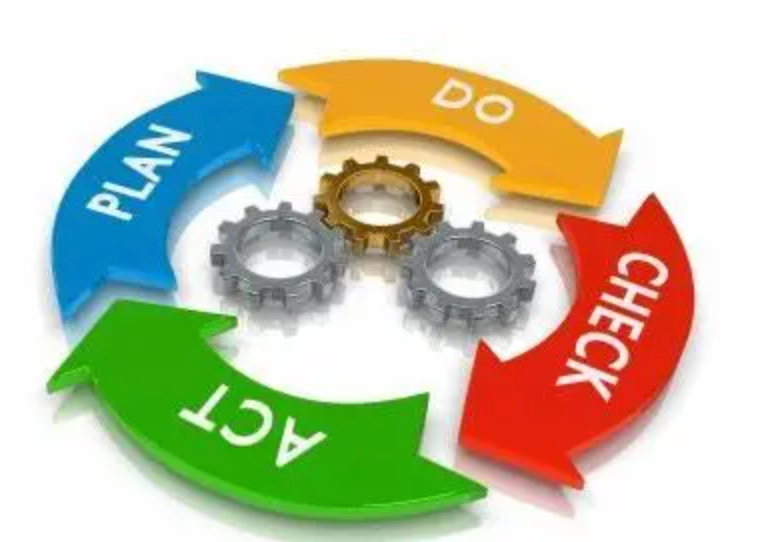

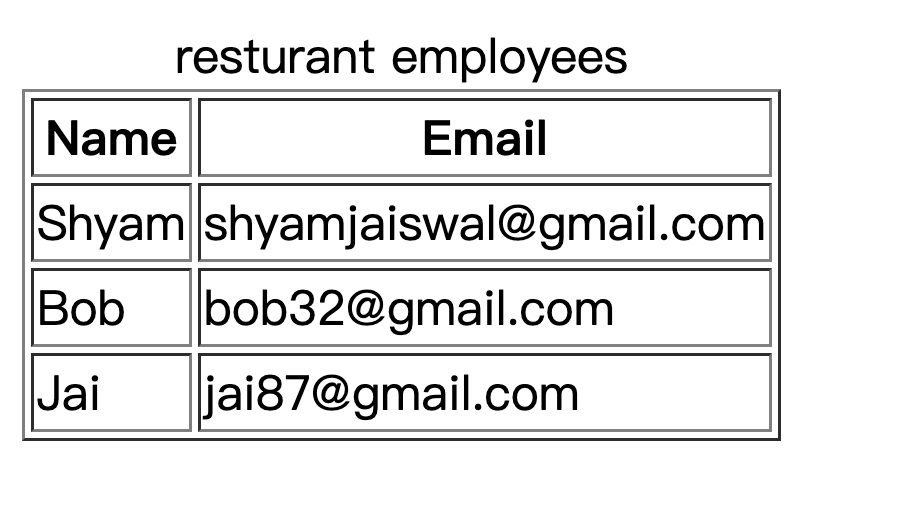

## 八、调试与验证清单

- 模型名称是否已通过 `ollama list` 确认，服务是否监听 `127.0.0.1:11434`？
- system Prompt 是否明确角色、任务和允许的输出集合？
- few-shot 样例是否覆盖边界情况，示例标签是否正确？
- 抽取任务的 Schema 是否固定，字段缺失时是否有统一返回值？
- JSON 输出是否能通过 `json.loads()` 解析？
- 分类和匹配结果是否需要清理 Markdown、解释文本或标点？
- 是否用一组固定测试样本比较 Prompt 迭代前后的结果？


## 九、本章总结

- 金融大模型应用的关键是任务定义、Prompt 设计和输出约束，而不是盲目增加模型参数。
- 分类用类别集合和 few-shot 样例；抽取用 Schema 和 JSON；匹配用少量“是/不是”示例并限制输出。
- 代码通过 Ollama 调用 Qwen2.5，保存了从 Prompt 初始化到推理、清洗和展示的完整链路。
- 结构化输出和后处理同样重要：模型回答可读，不代表能直接被程序可靠使用。
- Prompt 需要经过多轮测试和迭代，最终以业务准确率、格式稳定性和可维护性作为判断标准。
